# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments.
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [2]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [3]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [4]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('west')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`.

In [5]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0

    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action)

        if (action == "suck"):
            num_cleaned = num_cleaned + 1

    return num_cleaned



Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [6]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: east
step 1 - action: east
step 2 - action: south
step 3 - action: south
step 4 - action: north
step 5 - action: west
step 6 - action: east
step 7 - action: north
step 8 - action: suck
step 9 - action: suck
step 10 - action: west
step 11 - action: south
step 12 - action: south
step 13 - action: east
step 14 - action: east
step 15 - action: east
step 16 - action: west
step 17 - action: south
step 18 - action: south
step 19 - action: north


2

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`.
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details.
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [7]:
# Description: Môi trường mô phỏng (simulation environment) cho robot hút bụi.
# - Khởi tạo phòng n x n, mỗi ô có xác suất bẩn là p.
# - Vị trí của agent được khởi tạo ngẫu nhiên.
# - Hàm vòng lặp cấp percepts (bumpers, dirty) cho agent và nhận action.
# - Hành động hợp lệ sẽ làm thay đổi vị trí hoặc làm sạch ô hiện tại.
# - Mỗi action tốn 1 đơn vị năng lượng. Vòng lặp dừng khi phòng sạch hoặc cạn năng lượng.

import numpy as np

def simulation_environment(agent_function, n=5, p=0.2, max_steps=1000, verbose=False):
    # Khởi tạo trạng thái phòng (True = Bẩn, False = Sạch)
    room = np.random.choice([True, False], size=(n, n), p=[p, 1-p])

    # Khởi tạo vị trí ngẫu nhiên cho robot
    agent_pos = [np.random.randint(0, n), np.random.randint(0, n)]

    energy_consumed = 0

    if verbose:
        print(f"Trạng thái phòng ban đầu (True = Bẩn):\n{room}")
        print(f"Vị trí bắt đầu của Agent: {agent_pos}\n")

    for step in range(max_steps):
        # Kiểm tra xem toàn bộ phòng đã sạch chưa
        if not np.any(room):
            if verbose:
                print(f"Toàn bộ phòng đã sạch! Tổng số năng lượng: {energy_consumed}")
            break

        # 1. Thu thập dữ liệu cảm biến (Percepts)
        r, c = agent_pos
        dirty = room[r, c]
        bumpers = {
            "north": r == 0,
            "east": c == n - 1,
            "south": r == n - 1,
            "west": c == 0
        }

        # 2. Gọi Agent Function
        action = agent_function(bumpers, dirty)
        energy_consumed += 1 # Mỗi hành động tốn 1 năng lượng

        if verbose:
            print(f"Bước {step}: Vị trí {agent_pos} | Bẩn: {dirty} | Hành động: {action}")

        # 3. Phản hồi lại hành động của Agent
        if action == "suck":
            room[r, c] = False
        elif action == "north" and not bumpers["north"]:
            agent_pos[0] -= 1
        elif action == "south" and not bumpers["south"]:
            agent_pos[0] += 1
        elif action == "west" and not bumpers["west"]:
            agent_pos[1] -= 1
        elif action == "east" and not bumpers["east"]:
            agent_pos[1] += 1

    return energy_consumed

Show that your environment works with the simple randomized agent from above.

In [8]:
# Chạy mô phỏng để chứng minh môi trường hoạt động tốt với simple_randomized_agent
# Cài đặt seed để kết quả in ra luôn giống nhau trong mỗi lần chạy thử
np.random.seed(42)

print("Bắt đầu mô phỏng với Simple Randomized Agent:")
performance_score = simulation_environment(
    agent_function=simple_randomized_agent,
    n=5,
    p=0.2,
    max_steps=50,  # Đặt số bước nhỏ để dễ quan sát output
    verbose=True
)

print(f"\nĐiểm hiệu suất (Số năng lượng tiêu thụ): {performance_score}")

Bắt đầu mô phỏng với Simple Randomized Agent:
Trạng thái phòng ban đầu (True = Bẩn):
[[False False False False  True]
 [ True  True False False False]
 [ True False False False  True]
 [ True False False False False]
 [False  True False False False]]
Vị trí bắt đầu của Agent: [2, 3]

Bước 0: Vị trí [2, 3] | Bẩn: False | Hành động: south
Bước 1: Vị trí [3, 3] | Bẩn: False | Hành động: north
Bước 2: Vị trí [2, 3] | Bẩn: False | Hành động: west
Bước 3: Vị trí [2, 2] | Bẩn: False | Hành động: suck
Bước 4: Vị trí [2, 2] | Bẩn: False | Hành động: west
Bước 5: Vị trí [2, 1] | Bẩn: False | Hành động: suck
Bước 6: Vị trí [2, 1] | Bẩn: False | Hành động: north
Bước 7: Vị trí [1, 1] | Bẩn: True | Hành động: east
Bước 8: Vị trí [1, 2] | Bẩn: False | Hành động: south
Bước 9: Vị trí [2, 2] | Bẩn: False | Hành động: north
Bước 10: Vị trí [1, 2] | Bẩn: False | Hành động: south
Bước 11: Vị trí [2, 2] | Bẩn: False | Hành động: east
Bước 12: Vị trí [2, 3] | Bẩn: False | Hành động: east
Bước 13: Vị trí [2

## Task 2:  Implement a simple reflex agent [10 Points]

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [9]:
# Description: Simple reflex agent
# - Luật 1: Nếu cảm biến báo vị trí hiện tại bẩn (dirty == True), trả về hành động "suck".
# - Luật 2: Nếu sạch, agent tìm các hướng không có tường (dựa vào dictionary bumpers).
# - Luật 3: Chọn ngẫu nhiên một hướng đi hợp lệ từ các hướng vừa tìm được để tránh va chạm vô ích.

import numpy as np

def simple_reflex_agent(bumpers, dirty):
    # Phản xạ với bụi bẩn
    if dirty:
        return "suck"

    # Phản xạ với tường: tạo danh sách các hướng không bị vướng tường
    possible_moves = []
    if not bumpers["north"]:
        possible_moves.append("north")
    if not bumpers["south"]:
        possible_moves.append("south")
    if not bumpers["west"]:
        possible_moves.append("west")
    if not bumpers["east"]:
        possible_moves.append("east")

    # Chọn ngẫu nhiên một hướng trong số các hướng an toàn
    return np.random.choice(possible_moves)

Show how the agent works with your environment.

In [10]:
# Kiểm thử xem simple_reflex_agent hoạt động thế nào trong simulation_environment
# Cài đặt seed để kết quả in ra luôn giống nhau trong mỗi lần chạy thử
np.random.seed(42)

print("Bắt đầu mô phỏng với Simple Reflex Agent:")
performance_score = simulation_environment(
    agent_function=simple_reflex_agent,
    n=5,
    p=0.2,
    max_steps=200, # Đặt max_steps đủ lớn để agent có thể dọn sạch phòng 5x5
    verbose=True
)

print(f"\nĐiểm hiệu suất (Số năng lượng tiêu thụ): {performance_score}")

Bắt đầu mô phỏng với Simple Reflex Agent:
Trạng thái phòng ban đầu (True = Bẩn):
[[False False False False  True]
 [ True  True False False False]
 [ True False False False  True]
 [ True False False False False]
 [False  True False False False]]
Vị trí bắt đầu của Agent: [2, 3]

Bước 0: Vị trí [2, 3] | Bẩn: False | Hành động: west
Bước 1: Vị trí [2, 2] | Bẩn: False | Hành động: east
Bước 2: Vị trí [2, 3] | Bẩn: False | Hành động: east
Bước 3: Vị trí [2, 4] | Bẩn: True | Hành động: suck
Bước 4: Vị trí [2, 4] | Bẩn: False | Hành động: north
Bước 5: Vị trí [1, 4] | Bẩn: False | Hành động: west
Bước 6: Vị trí [1, 3] | Bẩn: False | Hành động: north
Bước 7: Vị trí [0, 3] | Bẩn: False | Hành động: east
Bước 8: Vị trí [0, 4] | Bẩn: True | Hành động: suck
Bước 9: Vị trí [0, 4] | Bẩn: False | Hành động: south
Bước 10: Vị trí [1, 4] | Bẩn: False | Hành động: north
Bước 11: Vị trí [0, 4] | Bẩn: False | Hành động: south
Bước 12: Vị trí [1, 4] | Bẩn: False | Hành động: west
Bước 13: Vị trí [1, 3] |

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

**Mô tả State và Chiến thuật (State Representation & Strategy):**
- **Vấn đề:** Agent ban đầu không biết tọa độ của mình, nhưng biết phòng có kích thước $n \times n$ (mặc định $n=5$).
- **State (Trạng thái lưu trữ):** Sử dụng một biến từ điển (dictionary) `state` gồm 2 thành phần chính:
  - `phase`: Giai đoạn hiện tại của robot (`find_north`, `find_west`, `sweep`).
  - `direction`: Hướng di chuyển ngang hiện tại trong lúc quét phòng (`east` hoặc `west`).
- **Chiến thuật 2 giai đoạn:**
  - **Giai đoạn 1 (Định vị - Localization):** Robot di chuyển liên tục về hướng Bắc (North) cho đến khi đụng tường `bumpers["north"] == True`. Sau đó, nó di chuyển về hướng Tây (West) cho tới khi đụng tường `bumpers["west"] == True`. Lúc này, robot chắc chắn đang ở góc trên cùng bên trái (tọa độ 0, 0).
  - **Giai đoạn 2 (Quét phòng - Sweeping):** Robot bắt đầu di chuyển sang hướng Đông (East) cho đến khi đụng tường, sau đó nhích xuống Nam (South) 1 bước, đổi hướng sang Tây (West) cho đến đụng tường, nhích xuống Nam 1 bước, và tiếp tục lặp lại theo hình zigzag.
- **Phản xạ ưu tiên:** Bất kể ở giai đoạn nào, nếu cảm biến báo bẩn (`dirty == True`), robot sẽ ưu tiên trả về hành động `"suck"`.

In [12]:
# Sử dụng Python closure để lưu trữ state cho Agent mà không cần dùng Lập trình hướng đối tượng (OOP) quá phức tạp.
# Bằng cách này, mỗi khi gọi get_model_based_agent(), ta sẽ tạo ra một agent mới với state được reset,
# rất hữu ích cho Task 4 khi cần chạy lại mô phỏng 100 lần.

def get_model_based_agent():
    # Khởi tạo trạng thái ban đầu
    state = {
        "phase": "find_north",
        "direction": "east"
    }

    def model_based_agent(bumpers, dirty):
        # Ưu tiên số 1: Hút bụi nếu ô hiện tại bẩn (không làm thay đổi quy trình di chuyển)
        if dirty:
            return "suck"

        # Giai đoạn 1a: Đi lên sát tường Bắc
        if state["phase"] == "find_north":
            if not bumpers["north"]:
                return "north"
            else:
                state["phase"] = "find_west" # Đã chạm tường Bắc, chuyển sang tìm tường Tây

        # Giai đoạn 1b: Đi sang sát tường Tây (Góc trên cùng bên trái)
        if state["phase"] == "find_west":
            if not bumpers["west"]:
                return "west"
            else:
                state["phase"] = "sweep" # Đã đến góc (0,0), bắt đầu quét

        # Giai đoạn 2: Quét phòng theo hình zigzag
        if state["phase"] == "sweep":
            if state["direction"] == "east":
                if not bumpers["east"]:
                    return "east"
                else:
                    # Chạm tường Đông -> Đổi hướng sang Tây và bước xuống Nam 1 ô
                    state["direction"] = "west"
                    if not bumpers["south"]:
                        return "south"

            elif state["direction"] == "west":
                if not bumpers["west"]:
                    return "west"
                else:
                    # Chạm tường Tây -> Đổi hướng sang Đông và bước xuống Nam 1 ô
                    state["direction"] = "east"
                    if not bumpers["south"]:
                        return "south"

        # Fallback an toàn (trường hợp đã quét xong nhưng môi trường chưa kết thúc)
        return "suck"

    return model_based_agent

Show how the agent works with your environment.

In [13]:
# Chạy mô phỏng cho Model-based Reflex Agent
import numpy as np

# Cài đặt seed để kết quả in ra luôn giống nhau trong mỗi lần chạy
np.random.seed(42)

print("Bắt đầu mô phỏng với Model-based Reflex Agent:")

# Khởi tạo agent mới (reset trạng thái)
my_model_agent = get_model_based_agent()

performance_score = simulation_environment(
    agent_function=my_model_agent,
    n=5,
    p=0.2,
    max_steps=200,
    verbose=True
)

print(f"\nĐiểm hiệu suất (Số năng lượng tiêu thụ): {performance_score}")

Bắt đầu mô phỏng với Model-based Reflex Agent:
Trạng thái phòng ban đầu (True = Bẩn):
[[False False False False  True]
 [ True  True False False False]
 [ True False False False  True]
 [ True False False False False]
 [False  True False False False]]
Vị trí bắt đầu của Agent: [2, 3]

Bước 0: Vị trí [2, 3] | Bẩn: False | Hành động: north
Bước 1: Vị trí [1, 3] | Bẩn: False | Hành động: north
Bước 2: Vị trí [0, 3] | Bẩn: False | Hành động: west
Bước 3: Vị trí [0, 2] | Bẩn: False | Hành động: west
Bước 4: Vị trí [0, 1] | Bẩn: False | Hành động: west
Bước 5: Vị trí [0, 0] | Bẩn: False | Hành động: east
Bước 6: Vị trí [0, 1] | Bẩn: False | Hành động: east
Bước 7: Vị trí [0, 2] | Bẩn: False | Hành động: east
Bước 8: Vị trí [0, 3] | Bẩn: False | Hành động: east
Bước 9: Vị trí [0, 4] | Bẩn: True | Hành động: suck
Bước 10: Vị trí [0, 4] | Bẩn: False | Hành động: south
Bước 11: Vị trí [1, 4] | Bẩn: False | Hành động: west
Bước 12: Vị trí [1, 3] | Bẩn: False | Hành động: west
Bước 13: Vị trí [1, 

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents.
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cài đặt thông số
sizes = [5, 10, 100]
runs = 100
p_dirt = 0.2

# Khởi tạo từ điển để lưu kết quả
results_data = {
    "Size": [f"{n}x{n}" for n in sizes],
    "Randomized Agent": [],
    "Simple Reflex Agent": [],
    "Model-based Reflex Agent": []
}


for n in sizes:
    # Đặt giới hạn bước đi để tránh treo máy với các agent ngẫu nhiên trong phòng lớn
    # Phòng càng lớn, max_steps cần đủ dài, nhưng vẫn phải có giới hạn
    max_steps = n * n * 50

    score_random = []
    score_reflex = []
    score_model = []

    for i in range(runs):
        # 1. Randomized Agent
        score_random.append(simulation_environment(
            simple_randomized_agent, n=n, p=p_dirt, max_steps=max_steps, verbose=False
        ))

        # 2. Simple Reflex Agent
        score_reflex.append(simulation_environment(
            simple_reflex_agent, n=n, p=p_dirt, max_steps=max_steps, verbose=False
        ))

        # 3. Model-based Reflex Agent
        # Cần khởi tạo lại agent mỗi lần chạy để reset state
        model_agent = get_model_based_agent()
        score_model.append(simulation_environment(
            model_agent, n=n, p=p_dirt, max_steps=max_steps, verbose=False
        ))

    # Tính trung bình cộng của 100 lần chạy
    results_data["Randomized Agent"].append(np.mean(score_random))
    results_data["Simple Reflex Agent"].append(np.mean(score_reflex))
    results_data["Model-based Reflex Agent"].append(np.mean(score_model))

# Tạo bảng hiển thị bằng Pandas
df_results = pd.DataFrame(results_data)
print("Bảng kết quả trung bình:")
display(df_results)

Bảng kết quả trung bình:


,Size,Randomized Agent,Simple Reflex Agent,Model-based Reflex Agent
0,5x5,446.30,103.02,28.70
1,10x10,3010.99,944.04,123.21
2,100x100,500000.00,333514.29,12099.59


Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     | | | |
| 10x10   | | | |
| 100x100 | | | |

Add charts to compare the performance of the different agents.

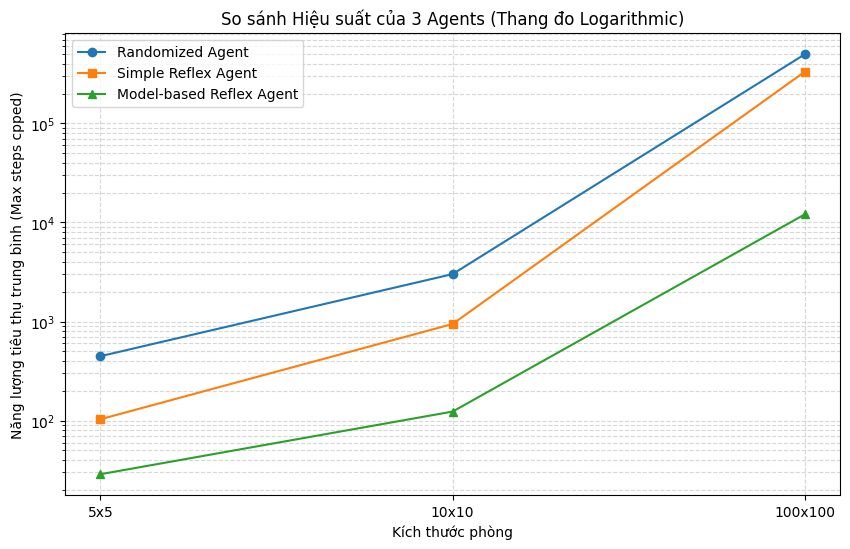

In [15]:
# Vẽ biểu đồ so sánh hiệu suất
plt.figure(figsize=(10, 6))

# Do sự chênh lệch số liệu giữa 5x5 và 100x100 là rất lớn, sử dụng thang đo Logarithmic (log scale)
plt.plot(df_results["Size"], df_results["Randomized Agent"], marker='o', label="Randomized Agent")
plt.plot(df_results["Size"], df_results["Simple Reflex Agent"], marker='s', label="Simple Reflex Agent")
plt.plot(df_results["Size"], df_results["Model-based Reflex Agent"], marker='^', label="Model-based Reflex Agent")

plt.yscale('log') # Thang đo Log giúp dễ quan sát chênh lệch ở nhiều cấp độ
plt.title("So sánh Hiệu suất của 3 Agents (Thang đo Logarithmic)")
plt.xlabel("Kích thước phòng")
plt.ylabel("Năng lượng tiêu thụ trung bình (Max steps cpped)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

### Phân tích và Thảo luận Kết quả (Discussion)

Dựa trên dữ liệu mô phỏng, chúng ta có thể rút ra các điểm khác biệt rõ rệt giữa 3 agent:

1. **Randomized Agent:**
   - **Hiệu suất kém nhất.** Vì không quan tâm đến cảm biến, agent này tiêu tốn rất nhiều hành động vô ích (đâm vào tường, không hút rác khi đứng trên ô bẩn). Ở không gian lớn (100x100), nó gần như luôn chạm tới giới hạn `max_steps` mà vẫn chưa dọn sạch phòng.

2. **Simple Reflex Agent:**
   - **Hiệu suất trung bình.** Nhờ có cảm biến, nó luôn hút rác khi cần và biết tránh đâm vào tường. Tuy nhiên, do cách di chuyển ngẫu nhiên (chỉ là tránh va chạm vô nghĩa), nó mất rất nhiều thời gian để vô tình đi qua tất cả các ô trong phòng. Ở môi trường 5x5 và 10x10, nó hoạt động chấp nhận được, nhưng ở 100x100, hiệu suất giảm sút nghiêm trọng do hiện tượng di chuyển trùng lặp (chạy vòng quanh các khu vực đã sạch).

3. **Model-based Reflex Agent:**
   - **Hiệu suất tối ưu và ổn định nhất.** Nhờ có bộ nhớ (state) lưu lại giai đoạn và hướng di chuyển hiện tại, agent này có khả năng định vị và quét phòng theo thuật toán zigzag bài bản. Số bước (năng lượng) tiêu tốn gần như xấp xỉ tỉ lệ thuận với tổng số ô trong phòng cộng thêm vài bước định vị ban đầu (khoảng $N^2 + \text{steps to corner}$). Nó luôn đảm bảo dọn sạch phòng 100x100 với mức chi phí năng lượng ít nhất và không bị phụ thuộc vào yếu tố may rủi.

## Task 5: Robustness of the agent implementations [10 Points]

Describe how **your agent implementations** will perform

* if it is put into a rectangular room with unknown size,
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

### Đánh giá tính bền vững (Robustness) của các Agents

Dựa trên cách cài đặt của 3 agents (Randomized, Simple Reflex, Model-based Reflex), dưới đây là phân tích về cách chúng phản ứng với các điều kiện môi trường phức tạp hơn:

**1. Phòng hình chữ nhật không rõ kích thước (Rectangular room with unknown size):**
* **Model-based Reflex Agent:** Hoạt động **hoàn hảo**. Thuật toán của agent này dựa vào việc đi cho đến khi đụng tường (`bumpers` trả về `True`) để định vị góc và chuyển hàng (sweep), hoàn toàn không sử dụng biến kích thước `n`. Do đó, nó vẫn quét sạch phòng chữ nhật bất kỳ.
* **Simple Reflex / Randomized:** Không bị ảnh hưởng về mặt logic (chúng vốn không quan tâm kích thước), nhưng thời gian và năng lượng tiêu tốn sẽ tăng theo cấp số nhân nếu phòng quá lớn.

**2. Phòng có hình dạng bất quy tắc (Irregular shape - VD: Hành lang nối 2 phòng):**
* **Model-based Reflex Agent:** Sẽ **thất bại**. Thuật toán zigzag giả định một không gian hình chữ nhật nguyên vẹn. Nếu gặp góc khuất hoặc hành lang hẹp, nó sẽ tưởng đó là rìa phòng, tự động chuyển xuống hướng Nam và bỏ sót toàn bộ các khu vực lồi lõm hoặc phòng thứ 2. Nó cũng không biết cách quay lại.
* **Simple Reflex Agent:** Sẽ **chậm nhưng dọn được**. Nhờ đi ngẫu nhiên, nó sẽ từ từ len lỏi qua hành lang và khám phá các phòng khác, nhưng tốn lượng lớn năng lượng.

**3. Phòng có chướng ngại vật (Obstacles):**
* **Model-based Reflex Agent:** Sẽ **thất bại**. Chướng ngại vật sẽ kích hoạt cảm biến bumper. Agent sẽ nhầm tưởng chướng ngại vật là bức tường ngoài cùng, dẫn đến việc nó quay đầu và nhích xuống Nam quá sớm. Toàn bộ khu vực phía sau chướng ngại vật sẽ bị bỏ sót hoàn toàn.
* **Simple Reflex Agent:** **Hoạt động tốt**. Khi đụng chướng ngại vật, cảm biến bumper sẽ loại bỏ hướng đó khỏi các bước đi an toàn, agent sẽ bẻ lái sang hướng ngẫu nhiên khác để tiếp tục đi dọn dẹp.

**4. Cảm biến bụi bẩn không hoàn hảo (Lỗi 10% - Imperfect dirt sensor):**
* **Model-based Reflex Agent:** Bị **ảnh hưởng rất nặng nề**. Lỗi 10% (dirty thành clean) sẽ khiến agent bỏ qua ô bẩn đó. Vì thuật toán quét zigzag chỉ đi qua mỗi ô đúng **một lần duy nhất**, ô rác bị bỏ sót sẽ vĩnh viễn không được dọn, khiến phòng không bao giờ đạt trạng thái sạch 100%. Lỗi (clean thành dirty) thì chỉ khiến nó tốn thêm 1 năng lượng để "suck" vô ích.
* **Simple Reflex Agent:** Có khả năng **khắc phục**. Dù bỏ sót rác ở lần đầu đi ngang qua, việc di chuyển ngẫu nhiên giúp nó có cơ hội quay lại ô đó trong tương lai và nhận diện lại.

**5. Cảm biến va chạm không hoàn hảo (Lỗi 10% không báo tường - Imperfect bumper sensor):**
* **Model-based Reflex Agent:** Bị **giảm hiệu suất nhưng không hỏng logic**. Khi đến sát tường mà cảm biến không kêu, agent sẽ cố gắng đi thẳng tiếp và đập mặt vào tường (tốn 1 năng lượng nhưng vị trí không đổi). Tuy nhiên, ở các bước (step) lặp lại ngay sau đó, nếu cảm biến báo lại đúng (90% cơ hội), nó sẽ nhận ra tường và rẽ hướng bình thường. Hệ quả là nó sẽ tốn nhiều bước/năng lượng hơn bình thường ở các mép tường.
* **Simple Reflex Agent:** Cũng sẽ thỉnh thoảng đâm vào tường (tốn 1 năng lượng vô ích) do tưởng hướng đó an toàn, nhưng sau đó sẽ tự động chọn hướng khác ở lượt tiếp theo.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares.

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [21]:
# Môi trường với cảm biến bụi bẩn lỗi 10%
import numpy as np

def simulation_environment_imperfect(agent_function, n=5, p=0.2, error_rate=0.1, max_steps=300, verbose=False):
    room = np.random.choice([True, False], size=(n, n), p=[p, 1-p])
    agent_pos = [np.random.randint(0, n), np.random.randint(0, n)]
    energy_consumed = 0

    for step in range(max_steps):
        if not np.any(room): # Dừng nếu thực tế phòng đã sạch
            if verbose: print(f"Phòng đã sạch hoàn toàn ở bước {step}!")
            break

        r, c = agent_pos
        actual_dirty = room[r, c]

        # Cảm biến lỗi: 10% lật ngược kết quả thực tế
        if np.random.rand() < error_rate:
            perceived_dirty = not actual_dirty
        else:
            perceived_dirty = actual_dirty

        bumpers = {
            "north": r == 0,
            "east": c == n - 1,
            "south": r == n - 1,
            "west": c == 0
        }

        action = agent_function(bumpers, perceived_dirty)
        energy_consumed += 1

        if action == "suck":
            room[r, c] = False
        elif action == "north" and not bumpers["north"]: agent_pos[0] -= 1
        elif action == "south" and not bumpers["south"]: agent_pos[0] += 1
        elif action == "west" and not bumpers["west"]: agent_pos[1] -= 1
        elif action == "east" and not bumpers["east"]: agent_pos[1] += 1

    # Tính điểm: Tổng năng lượng + Phạt nặng (50 điểm) cho mỗi ô chưa được làm sạch
    uncleaned_squares = np.sum(room)
    penalty = uncleaned_squares * 50
    total_cost = energy_consumed + penalty

    if verbose:
        print(f"Tổng năng lượng: {energy_consumed}, Ô chưa sạch: {uncleaned_squares}, Điểm phạt: {penalty}")
    return total_cost

In [23]:
# Agent khắc phục lỗi cảm biến bằng cách quét phòng lặp đi lặp lại
def get_robust_model_agent():
    state = {"phase": "find_north", "direction": "east"}

    def robust_agent(bumpers, dirty):
        if dirty:
            return "suck"

        if state["phase"] == "find_north":
            if not bumpers["north"]: return "north"
            else: state["phase"] = "find_west"

        if state["phase"] == "find_west":
            if not bumpers["west"]: return "west"
            else: state["phase"] = "sweep"

        if state["phase"] == "sweep":
            if state["direction"] == "east":
                if not bumpers["east"]: return "east"
                else:
                    if not bumpers["south"]:
                        state["direction"] = "west"
                        return "south"
                    else:
                        # Chạm góc Đông Nam -> Reset về chu kỳ ban đầu để quét lại phòng
                        state["phase"] = "find_north"
                        return "west"

            elif state["direction"] == "west":
                if not bumpers["west"]: return "west"
                else:
                    if not bumpers["south"]:
                        state["direction"] = "east"
                        return "south"
                    else:
                        # Chạm góc Tây Nam -> Reset
                        state["phase"] = "find_north"
                        return "east"
        return "suck"
    return robust_agent

# Chạy thử so sánh hiệu suất
np.random.seed(42)

print("--- Agent cũ ---")
old_agent = get_model_based_agent() # Lấy từ Task 3
score_old = simulation_environment_imperfect(old_agent, max_steps=300, verbose=True)
print(f"Chi phí Agent cũ: {score_old}\n")

print("--- Robust Agent  ---")
robust_agent = get_robust_model_agent()
score_robust = simulation_environment_imperfect(robust_agent, max_steps=300, verbose=True)
print(f"Chi phí Robust Agent: {score_robust}")

--- Agent cũ ---
Phòng đã sạch hoàn toàn ở bước 39!
Tổng năng lượng: 39, Ô chưa sạch: 0, Điểm phạt: 0
Chi phí Agent cũ: 39

--- Robust Agent  ---
Phòng đã sạch hoàn toàn ở bước 43!
Tổng năng lượng: 43, Ô chưa sạch: 0, Điểm phạt: 0
Chi phí Robust Agent: 43


## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can.

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [24]:
# Môi trường tích hợp chướng ngại vật
def simulation_environment_obstacles(agent_function, n=5, p_dirt=0.2, p_obs=0.1, max_steps=500, verbose=False):
    # Khởi tạo rác và chướng ngại vật
    room = np.random.choice([True, False], size=(n, n), p=[p_dirt, 1-p_dirt])
    obstacles = np.random.choice([True, False], size=(n, n), p=[p_obs, 1-p_obs])

    # Ô có chướng ngại vật thì không thể có rác
    room[obstacles] = False

    # Tìm vị trí hợp lệ cho agent khởi đầu (không nằm đè lên chướng ngại vật)
    agent_pos = [np.random.randint(0, n), np.random.randint(0, n)]
    while obstacles[agent_pos[0], agent_pos[1]]:
        agent_pos = [np.random.randint(0, n), np.random.randint(0, n)]

    energy_consumed = 0
    if verbose: print(f"Obstacles layout (True = Vật cản):\n{obstacles}\n")

    for step in range(max_steps):
        if not np.any(room):
            if verbose: print(f"Đã dọn sạch phòng! Năng lượng: {energy_consumed}")
            break

        r, c = agent_pos

        # Cảm biến tường VÀ cảm biến chướng ngại vật
        bumpers = {
            "north": r == 0 or obstacles[r-1, c],
            "south": r == n - 1 or obstacles[r+1, c],
            "west": c == 0 or obstacles[r, c-1],
            "east": c == n - 1 or obstacles[r, c+1]
        }

        action = agent_function(bumpers, room[r, c])
        energy_consumed += 1

        if action == "suck":
            room[r, c] = False
        elif action == "north" and not bumpers["north"]: agent_pos[0] -= 1
        elif action == "south" and not bumpers["south"]: agent_pos[0] += 1
        elif action == "west" and not bumpers["west"]: agent_pos[1] -= 1
        elif action == "east" and not bumpers["east"]: agent_pos[1] += 1

    return energy_consumed

In [25]:
# Cấu trúc của DFS Agent xử lý môi trường vô định có chướng ngại vật
def get_dfs_agent():
    state = {
        "pos": (0, 0),             # Tọa độ tương đối giả định ban đầu
        "visited": set([(0, 0)]),  # Lưu các ô đã đi qua
        "path_stack": []           # Ngăn xếp để backtrack (quay lui)
    }

    # Mapping vector hướng đi
    moves = {"north": (-1, 0), "south": (1, 0), "east": (0, 1), "west": (0, -1)}
    back_moves = {"north": "south", "south": "north", "east": "west", "west": "east"}

    def dfs_agent(bumpers, dirty):
        if dirty:
            return "suck"

        curr_r, curr_c = state["pos"]

        # 1. Tìm các hướng chưa được khám phá và không bị chặn
        unvisited_moves = []
        for direction, (dr, dc) in moves.items():
            next_pos = (curr_r + dr, curr_c + dc)
            if not bumpers[direction] and next_pos not in state["visited"]:
                unvisited_moves.append(direction)

        # 2. Nếu có đường đi mới, tiến tới và ghi vào lịch sử
        if unvisited_moves:
            chosen_move = unvisited_moves[0]
            dr, dc = moves[chosen_move]
            state["pos"] = (curr_r + dr, curr_c + dc)
            state["visited"].add(state["pos"])
            state["path_stack"].append(chosen_move)
            return chosen_move

        # 3. Nếu ngõ cụt, Backtrack (quay lui) về ô trước đó
        if state["path_stack"]:
            last_move = state["path_stack"].pop()
            reverse_move = back_moves[last_move]
            dr, dc = moves[reverse_move]
            state["pos"] = (curr_r + dr, curr_c + dc)
            return reverse_move

        # 4. Nếu stack trống, đã khám phá toàn bộ không gian có thể đi được
        return "suck"

    return dfs_agent

# Chạy thử nghiệm
np.random.seed(15) # Dùng seed 15 để tạo ra một map chướng ngại vật rõ ràng
dfs_agent = get_dfs_agent()
score_dfs = simulation_environment_obstacles(dfs_agent, n=5, p_obs=0.15, max_steps=200, verbose=True)

Obstacles layout (True = Vật cản):
[[False  True False  True False]
 [False False False False False]
 [False False False False False]
 [ True  True  True False  True]
 [False  True  True False False]]

Đã dọn sạch phòng! Năng lượng: 15
